<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/5_5_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!sudo apt-get update
!sudo apt-get install libopencv-dev

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:7 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Fetched 3,917 B in 2s (2,335 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 37 not up

In [11]:
%%writefile xray_colorize.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <string>

int main() {

    std::vector<std::string> imageFiles = {
        "image1.jpg", "image2.jpg", "image3.jpg", "image4.jpg", "image.jpg"
    };

    for (size_t i = 0; i < imageFiles.size(); ++i) {
        cv::Mat originalImage = cv::imread(imageFiles[i], cv::IMREAD_COLOR);

        if (originalImage.empty()) {
            std::cerr << "Hata: " << imageFiles[i] << " okunamadi." << std::endl;
            continue;
        }

        // 1. Görüntüyü Gri Tonlamaya Çevirme
        cv::Mat grayImage;
        cv::cvtColor(originalImage, grayImage, cv::COLOR_BGR2GRAY);

        // 2. Güvenlik Operatörleri İçin Renklendirme (Pseudo-Coloring)
        cv::Mat colorizedImage;
        cv::applyColorMap(grayImage, colorizedImage, cv::COLORMAP_JET);

        // Sonuçları kaydetme
        std::string outName = "colorized_" + std::to_string(i + 1) + ".png";
        cv::imwrite(outName, colorizedImage);
        std::cout << imageFiles[i] << " islendi ve " << outName << " olarak kaydedildi." << std::endl;
    }

    return 0;
}

Overwriting xray_colorize.cpp


In [12]:
!g++ xray_colorize.cpp -o xray_colorize `pkg-config --cflags --libs opencv4`
!./xray_colorize

image1.jpg islendi ve colorized_1.png olarak kaydedildi.
image2.jpg islendi ve colorized_2.png olarak kaydedildi.
image3.jpg islendi ve colorized_3.png olarak kaydedildi.
image4.jpg islendi ve colorized_4.png olarak kaydedildi.
image.jpg islendi ve colorized_5.png olarak kaydedildi.


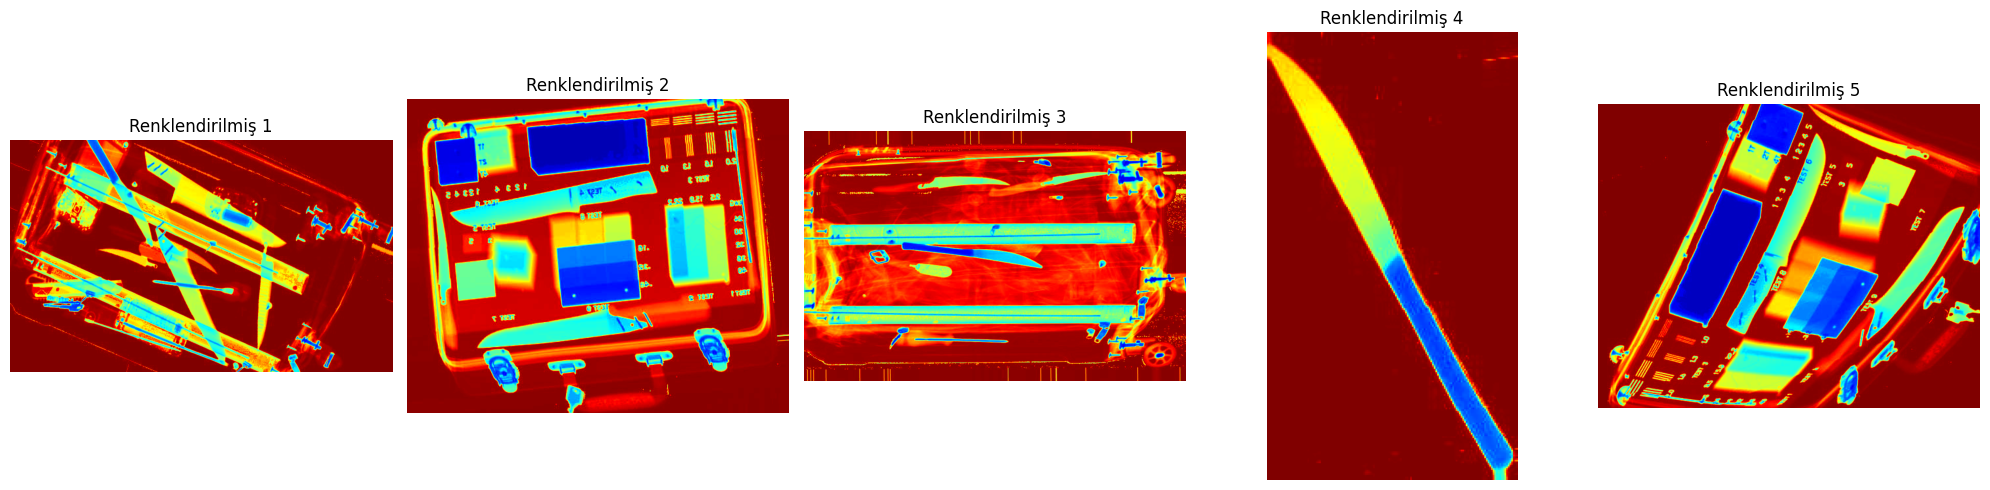

In [13]:
import matplotlib.pyplot as plt
import cv2

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i in range(5):
    img_path = f"colorized_{i+1}.png"
    img = cv2.imread(img_path)

    if img is not None:
        # OpenCV BGR formatında okuduğu için Matplotlib'e uygun RGB'ye çeviriyoruz
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[i].imshow(img_rgb)
        axes[i].set_title(f"Renklendirilmiş {i+1}")
        axes[i].axis('off')
    else:
        axes[i].set_title(f"Görsel {i+1} bulunamadı")
        axes[i].axis('off')

plt.tight_layout()
plt.show()